# Half Marathon — Training Pipeline


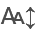

In [ ]:
import pandas as pd
from io import BytesIO
import boto3
import os  
from itables import init_notebook_mode
init_notebook_mode(all_interactive=True)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pycaret.regression import setup
import scipy.stats as stats

import itables.options as opt

# Zezwolenie na renderowanie HTML w tabelach
opt.allow_html = True

## Wczytujemy dane z Cloudflare R2

In [2]:
from dotenv import load_dotenv

load_dotenv()

True

In [3]:
s3 = boto3.client(
    service_name="s3",
    aws_access_key_id=os.getenv("AWS_ACCESS_KEY_ID"),
    aws_secret_access_key=os.getenv("AWS_SECRET_ACCESS_KEY"),
    # Endpoint jest potrzebny dlatego że używamy chmury innej niż AWS 
    endpoint_url=os.getenv("AWS_ENDPOINT_URL_S3"), 
    # Gdybyśmy używali AWS to musielibyśmy natomiast podać region
    region_name="auto",
)

In [7]:
BUCKET_NAME=os.getenv("BUCKET_NAME")

df_2023 = pd.read_csv(f"s3://{BUCKET_NAME}/data/halfmarathon_wroclaw_2023__final.csv", sep=";")
df_2024 = pd.read_csv(f"s3://{BUCKET_NAME}/data/halfmarathon_wroclaw_2024__final.csv", sep=";")




In [8]:
df_2023.head()

Miejsce  Numer startowy       Imię       Nazwisko   Miasto Kraj  \
0      1.0            1787     TOMASZ         GRYCKO      NaN  POL   
1      2.0               3  ARKADIUSZ  GARDZIELEWSKI  WROCŁAW  POL   
2      3.0            3832  KRZYSZTOF          HADAS   POZNAŃ  POL   
3      4.0             416     DAMIAN         DYDUCH    KĘPNO  POL   
4      5.0            8476      KAMIL      MAŃKOWSKI   MIRKÓW  POL   

                     Drużyna Płeć  Płeć Miejsce Kategoria wiekowa  ...  \
0     UKS BLIZA WŁADYSŁAWOWO    M           1.0               M30  ...   
1  ARKADIUSZGARDZIELEWSKI.PL    M           2.0               M30  ...   
2                        NaN    M           3.0               M20  ...   
3   AZS POLITECHNIKA OPOLSKA    M           4.0               M30  ...   
4            PARKRUN WROCŁAW    M           5.0               M20  ...   

   10 km Tempo  15 km Czas 15 km Miejsce Open  15 km Tempo  20 km Czas  \
0     2.926667    00:44:47                1.0     3.106667    01:01:43   
1     2.983333    00:45:26                2.0     3.143333    01:03:08   
2     3.123333    00:47:34                3.0     3.236667    01:05:09   
3     3.196667    00:48:49                5.0     3.330000    01:06:54   
4     3.276667    00:49:31                7.0     3.386667    01:07:27   

  20 km Miejsce Open  20 km Tempo  Tempo Stabilność      Czas     Tempo  
0                1.0     3.386667          0.031400  01:04:59  3.080509  
1                2.0     3.540000          0.038000  01:06:23  3.146875  
2                3.0     3.516667          0.024067  01:08:24  3.242475  
3                4.0     3.616667          0.025467  01:10:16  3.330963  
4                5.0     3.586667          0.023000  01:10:27  3.339654  

[5 rows x 27 columns]

In [9]:
df_2024.head()

Miejsce  Numer startowy     Imię    Nazwisko   Miasto Kraj  \
0      1.0             596  NIKODEM    DWORCZAK  KOŚCIAN  POL   
1      2.0             616  MATEUSZ      KACZOR    RADOM  POL   
2      3.0             154   PATRYK   KOZŁOWSKI    RADOM  POL   
3      4.0             591  DARIUSZ  BORATYŃSKI  WROCŁAW  POL   
4      5.0             521   SZYMON  DOROŻYŃSKI    LUBON  POL   

                               Drużyna Płeć  Płeć Miejsce Kategoria wiekowa  \
0                                  NaN    M           1.0               M20   
1                    RLTL OPTIMA RADOM    M           2.0               M20   
2                       RLTL-ZTE-RADOM    M           3.0               M20   
3          WOSIEK TEAM AZS AWF WROCŁAW    M           4.0               M20   
4  SZYMI TEAM AZS POLITECHNIKA OPOLSKA    M           5.0               M30   

   ...  10 km Tempo  15 km Czas 15 km Miejsce Open  15 km Tempo  20 km Czas  \
0  ...     2.920000    00:45:07                2.0     3.083333    01:00:33   
1  ...     2.920000    00:45:07                3.0     3.083333    01:00:38   
2  ...     2.920000    00:45:07                1.0     3.083333    01:00:59   
3  ...     3.110000    00:47:48                4.0     3.293333    01:05:40   
4  ...     3.153333    00:48:09                5.0     3.453333    01:06:05   

  20 km Miejsce Open  20 km Tempo  Tempo Stabilność      Czas     Tempo  
0                1.0     3.086667          0.007267  01:04:03  3.036265  
1                2.0     3.103333          0.008267  01:04:24  3.052856  
2                3.0     3.173333          0.012467  01:04:40  3.065497  
3                4.0     3.573333          0.028667  01:09:44  3.305681  
4                5.0     3.586667          0.039800  01:10:05  3.322272  

[5 rows x 27 columns]

## Łączymy dwa dataframy w jeden

In [12]:
df = pd.concat([df_2023, df_2024], ignore_index=True)

print(df.shape)

(21957, 27)


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21957 entries, 0 to 21956
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Miejsce                    18450 non-null  float64
 1   Numer startowy             21957 non-null  int64  
 2   Imię                       21957 non-null  object 
 3   Nazwisko                   21957 non-null  object 
 4   Miasto                     17774 non-null  object 
 5   Kraj                       18450 non-null  object 
 6   Drużyna                    8402 non-null   object 
 7   Płeć                       21946 non-null  object 
 8   Płeć Miejsce               18450 non-null  float64
 9   Kategoria wiekowa          21926 non-null  object 
 10  Kategoria wiekowa Miejsce  18430 non-null  float64
 11  Rocznik                    21472 non-null  float64
 12  5 km Czas                  18411 non-null  object 
 13  5 km Miejsce Open          18411 non-null  flo

## Sprawdzamy brakujące dane

In [14]:
df.isna().sum().rename('liczba braków')

Miejsce                       3507
Numer startowy                   0
Imię                             0
Nazwisko                         0
Miasto                        4183
Kraj                          3507
Drużyna                      13555
Płeć                            11
Płeć Miejsce                  3507
Kategoria wiekowa               31
Kategoria wiekowa Miejsce     3527
Rocznik                        485
5 km Czas                     3546
5 km Miejsce Open             3546
5 km Tempo                    3546
10 km Czas                    3530
10 km Miejsce Open            3530
10 km Tempo                   3562
15 km Czas                    3529
15 km Miejsce Open            3529
15 km Tempo                   3544
20 km Czas                    3518
20 km Miejsce Open            3518
20 km Tempo                   3535
Tempo Stabilność              3580
Czas                          2055
Tempo                         3507
Name: liczba braków, dtype: int64

In [15]:
df.isna().sum()/len(df)*100


Miejsce                      15.972127
Numer startowy                0.000000
Imię                          0.000000
Nazwisko                      0.000000
Miasto                       19.050872
Kraj                         15.972127
Drużyna                      61.734299
Płeć                          0.050098
Płeć Miejsce                 15.972127
Kategoria wiekowa             0.141185
Kategoria wiekowa Miejsce    16.063214
Rocznik                       2.208863
5 km Czas                    16.149747
5 km Miejsce Open            16.149747
5 km Tempo                   16.149747
10 km Czas                   16.076878
10 km Miejsce Open           16.076878
10 km Tempo                  16.222617
15 km Czas                   16.072323
15 km Miejsce Open           16.072323
15 km Tempo                  16.140639
20 km Czas                   16.022225
20 km Miejsce Open           16.022225
20 km Tempo                  16.099649
Tempo Stabilność             16.304595
Czas                          9.359202
Tempo                        15.972127
dtype: float64

### Zmieniam czas na sekundy

In [16]:
# Snippet pomocniczy - zmiana czasu na sekundy

def convert_time_to_seconds(time):
    if pd.isnull(time) or time in ['DNS', 'DNF']:
        return None
    time = time.split(":")
    return int(time[0]) * 3600 + int(time[1]) * 60 + int(time[2])

In [17]:
df["5 km Czas"] = df["5 km Czas"].apply(convert_time_to_seconds)
df["Czas"] = df["Czas"].apply(convert_time_to_seconds)

#### Usuwam zbędne kolumny

In [18]:
df=df[["Płeć","Kategoria wiekowa","5 km Czas","Czas"]].copy()
df.head()

Płeć Kategoria wiekowa  5 km Czas    Czas
0    M               M30      877.0  3899.0
1    M               M30      888.0  3983.0
2    M               M20      946.0  4104.0
3    M               M30      971.0  4216.0
4    M               M20      972.0  4227.0

In [19]:
df.isna().sum().rename('liczba braków')

Płeć                   11
Kategoria wiekowa      31
5 km Czas            3546
Czas                 3507
Name: liczba braków, dtype: int64

#### Usuwam braki

In [20]:
df=df.dropna()

In [21]:
df.isna().sum().rename('braki')

Płeć                 0
Kategoria wiekowa    0
5 km Czas            0
Czas                 0
Name: braki, dtype: int64

In [22]:
df.describe().T

count         mean          std     min     25%     50%     75%  \
5 km Czas  18393.0  1675.796499   247.501679     0.0  1505.0  1663.0  1837.0   
Czas       18393.0  7408.955798  1216.044385  3843.0  6556.0  7257.0  8154.0   

               max  
5 km Czas   3825.0  
Czas       12754.0

### Sprawdzamy outliers'y

In [23]:
# Z M30, M20, M40 → 20-30, 30-40
df["Wiek"] = df["Kategoria wiekowa"].str[1:].astype(int)
#df["Wiek"] = pd.cut(df["Wiek"], bins=[0, 25, 35, 45, 55, 100], labels=["do 25", "25-35", "35-45", "45-55","55+"])

df = df.drop("Kategoria wiekowa", axis=1)
df

Płeć  5 km Czas     Czas  Wiek
0        M      877.0   3899.0    30
1        M      888.0   3983.0    30
2        M      946.0   4104.0    20
3        M      971.0   4216.0    30
4        M      972.0   4227.0    20
...    ...        ...      ...   ...
19245    K     2610.0  11987.0    70
19246    K     2526.0  12068.0    40
19247    K     2960.0  12138.0    60
19248    K     2808.0  12512.0    40
19249    M     3014.0  12754.0    40

[18393 rows x 4 columns]

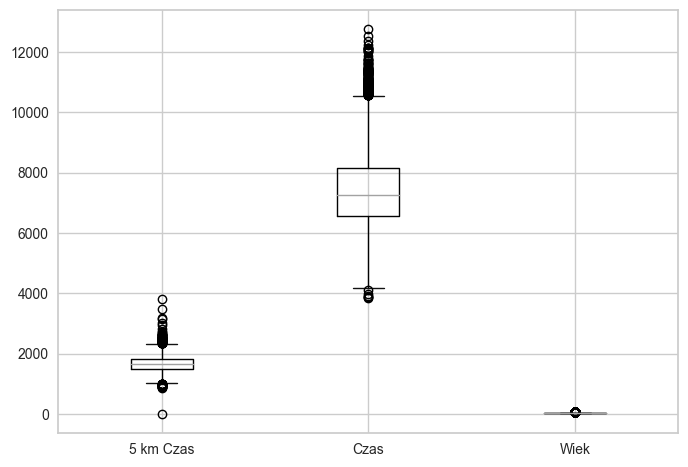

In [24]:
df.boxplot()
plt.show()

### Usuwamy outliers'y

In [25]:
def removing_outliers(df,factor=1.5):

    numeric = df.select_dtypes(include='number')
    cleaned_df = df.copy()
    for col in numeric:
        Q1=cleaned_df[col].quantile(0.25)
        Q3=cleaned_df[col].quantile(0.75)
        IQR=Q3-Q1

        lower_bound=Q1-1.5*IQR
        upper_bound=Q3+1.5*IQR

        cleaned_df=df[~((df[col]<lower_bound) | (df[col]>upper_bound))]

    return cleaned_df
cleaned_df=removing_outliers(df)

#### Wizualizacja outliersów

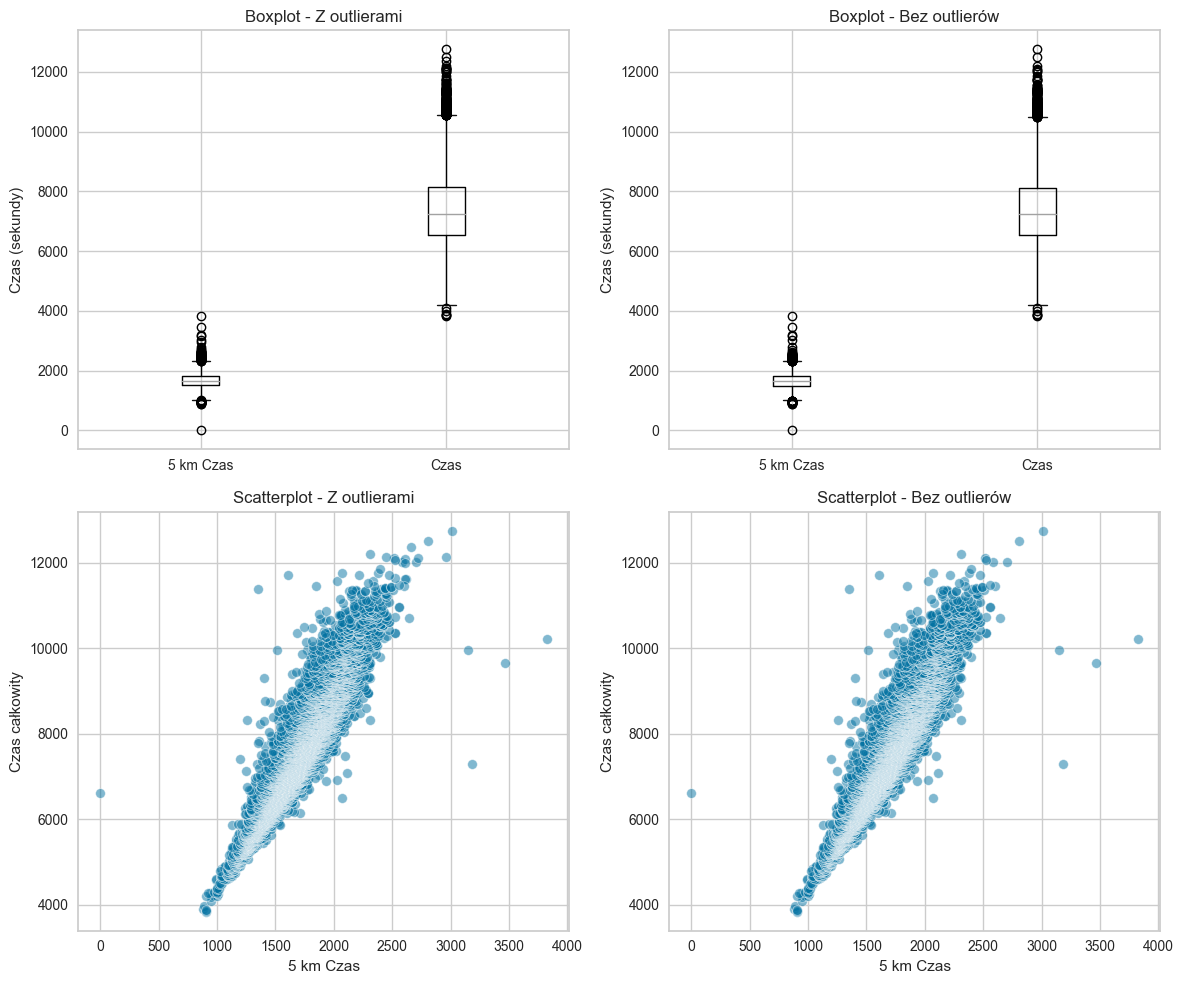

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# # # Górny wiersz - boxploty
df[['5 km Czas', 'Czas']].boxplot(ax=axes[0, 0])
axes[0, 0].set_title('Boxplot - Z outlierami')
axes[0, 0].set_ylabel('Czas (sekundy)')

cleaned_df[['5 km Czas', 'Czas']].boxplot(ax=axes[0, 1])
axes[0, 1].set_title('Boxplot - Bez outlierów')
axes[0, 1].set_ylabel('Czas (sekundy)')

# Dolny wiersz - scatterploty
sns.scatterplot(data=df, x='5 km Czas', y='Czas', ax=axes[1, 0], alpha=0.5)
axes[1, 0].set_title('Scatterplot - Z outlierami')
axes[1, 0].set_xlabel('5 km Czas')
axes[1, 0].set_ylabel('Czas całkowity')

sns.scatterplot(data=cleaned_df, x='5 km Czas', y='Czas', ax=axes[1, 1], alpha=0.5)
axes[1, 1].set_title('Scatterplot - Bez outlierów')
axes[1, 1].set_xlabel('5 km Czas')
axes[1, 1].set_ylabel('Czas całkowity')

plt.tight_layout()
plt.show()

### Sprawdzamy rozkład pod ewentualną transformację Yeo-Johnson

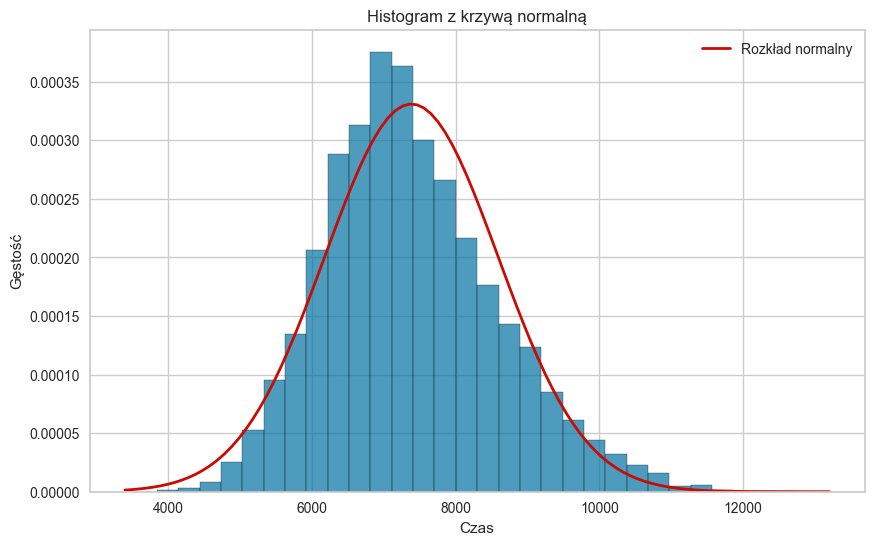

In [27]:
plt.figure(figsize=(10, 6))
plt.hist(cleaned_df['Czas'], bins=30, density=True, alpha=0.7, edgecolor='black')

# Dodaj krzywą normalną
mu = cleaned_df['Czas'].mean()
std = cleaned_df['Czas'].std()
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, mu, std)
plt.plot(x, p, 'r', linewidth=2, label='Rozkład normalny')

plt.xlabel('Czas')
plt.ylabel('Gęstość')
plt.title('Histogram z krzywą normalną')
plt.legend()
plt.show()

## Trenujemy model

In [28]:
exp =setup(
    data=df,
    target="Czas",
    session_id=123,
    categorical_features=["Płeć"],
    verbose=True,
)
best_model=exp.compare_models()

Description,Value
Session id,123
Target,Czas
Target type,Regression
Original data shape,"(18393, 4)"
Transformed data shape,"(18393, 4)"
Transformed train set shape,"(12875, 4)"
Transformed test set shape,"(5518, 4)"
Numeric features,2
Categorical features,1
Preprocess,True


,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
gbr,Gradient Boosting Regressor,303.5311,177565.5155,421.1059,0.8800,0.0532,0.0395,0.0320
lar,Least Angle Regression,306.5849,192101.3953,437.5147,0.8705,0.0588,0.0399,0.0080
lr,Linear Regression,306.5849,192101.3953,437.5147,0.8705,0.0588,0.0399,0.2230
omp,Orthogonal Matching Pursuit,306.6479,192157.9741,437.5770,0.8705,0.0588,0.0399,0.0060
llar,Lasso Least Angle Regression,306.5552,192082.3886,437.4926,0.8705,0.0588,0.0399,0.0080
br,Bayesian Ridge,306.5570,192082.1556,437.4923,0.8705,0.0588,0.0399,0.0060
en,Elastic Net,306.5571,192082.8665,437.4931,0.8705,0.0588,0.0399,0.0060
ridge,Ridge Regression,306.5849,192101.3840,437.5147,0.8705,0.0588,0.0399,0.0070
lasso,Lasso Regression,306.5552,192082.3889,437.4926,0.8705,0.0588,0.0399,0.1580
huber,Huber Regressor,302.7975,195727.6854,441.6936,0.8681,0.0649,0.0390,0.0090


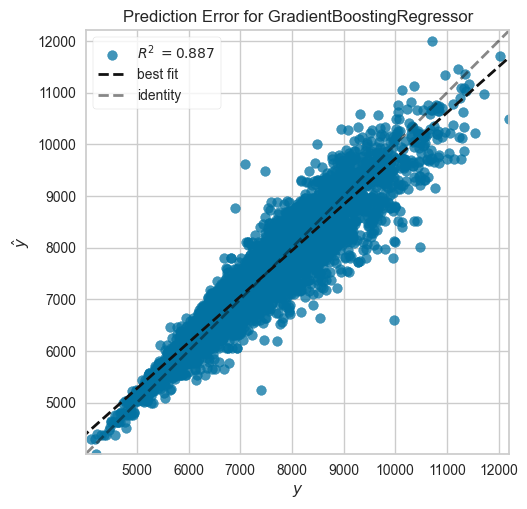

In [29]:
exp.plot_model(best_model, plot='error')

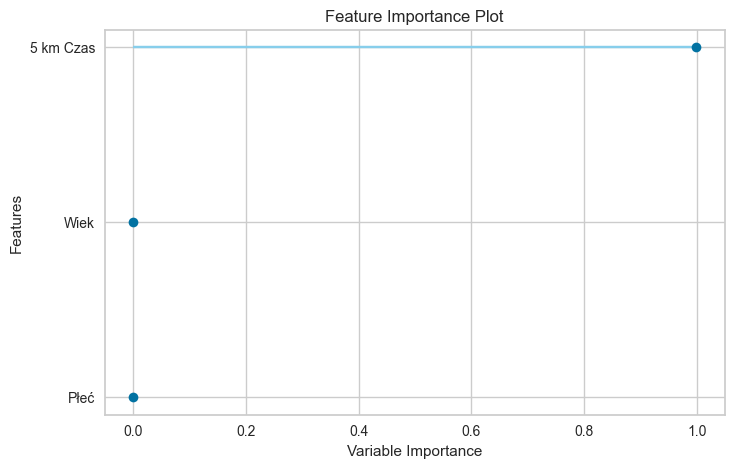

In [30]:
exp.plot_model(best_model,plot="feature")

In [31]:
tuned_model =exp. tune_model(
    best_model,
    optimize='R2',
    choose_better=True
)

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,323.2156,192912.0811,439.2176,0.8660,0.0557,0.0424
1,303.7104,168862.4973,410.9288,0.8798,0.0522,0.0400
2,317.2917,185204.9102,430.3544,0.8677,0.0546,0.0415
3,305.2013,198603.8247,445.6499,0.8573,0.0564,0.0398
4,318.5167,212688.1884,461.1813,0.8620,0.0573,0.0409
5,317.4000,193915.8655,440.3588,0.8721,0.0562,0.0413
6,327.9738,211175.5589,459.5384,0.8635,0.0579,0.0426
7,318.3624,191736.6926,437.8775,0.8690,0.0543,0.0410
8,324.2056,209619.0313,457.8417,0.8624,0.0566,0.0420


Fitting 10 folds for each of 10 candidates, totalling 100 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


### Uruchamiam pierwotny model na holdoutsecie

In [32]:
exp.predict_model(best_model)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Gradient Boosting Regressor,299.3177,165735.8697,407.1067,0.8873,0.0515,0.0392


Płeć  5 km Czas  Wiek    Czas  prediction_label
16502    M     1948.0    20  8135.0       8700.027772
18739    M     1983.0    30  9668.0       8814.398944
3255     M     1633.0    20  6950.0       7150.724457
9769     M     1418.0    30  5874.0       6222.117372
156      M     1182.0    40  5153.0       5229.710597
...    ...        ...   ...     ...               ...
13323    M     1671.0    20  7112.0       7357.105801
2861     M     1566.0    40  6808.0       6893.942194
14014    K     1639.0    40  7277.0       7181.520026
4770     K     1809.0    40  7458.0       8025.052301
4642     M     1611.0    40  7410.0       7101.992612

[5518 rows x 5 columns]

### Finalizujemy model

In [33]:
best_final_model = exp.finalize_model(best_model)
best_final_model

Pipeline(memory=Memory(location=None),
         steps=[('numerical_imputer',
                 TransformerWrapper(include=['5 km Czas', 'Wiek'],
                                    transformer=SimpleImputer())),
                ('categorical_imputer',
                 TransformerWrapper(include=['Płeć'],
                                    transformer=SimpleImputer(strategy='most_frequent'))),
                ('ordinal_encoding',
                 TransformerWrapper(include=['Płeć'],
                                    transformer=OrdinalEncoder(cols=['Płeć'],
                                                               handle_missing='return_nan',
                                                               mapping=[{'col': 'Płeć',
                                                                         'data_type': dtype('O'),
                                                                         'mapping': K      0
M      1
NaN   -1
dtype: int64}]))),
                ('clean_column_names',
                 TransformerWrapper(transformer=CleanColumnNames())),
                ('actual_estimator',
                 GradientBoostingRegressor(random_state=123))])

#### Zapisuję model lokalnie

In [34]:
exp.save_model(best_final_model,"halfmarathon_model")

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(include=['5 km Czas', 'Wiek'],
                                     transformer=SimpleImputer())),
                 ('categorical_imputer',
                  TransformerWrapper(include=['Płeć'],
                                     transformer=SimpleImputer(strategy='most_frequent'))),
                 ('ordinal_encoding',
                  TransformerWrapper(include=['Płeć'],
                                     transformer=OrdinalEncoder(cols=['Płeć'],
                                                                handle_missing='return_nan',
                                                                mapping=[{'col': 'Płeć',
                                                                          'data_type': dtype('O'),
                                                                          'mapping': K      0
 M      1
 NaN   -1
 dtype: int64}]))),
          

### Zapisujemy model do Cloudflare R2

In [38]:
try:
    
    s3.upload_file(
                Filename='halfmarathon_model.pkl',
                Bucket=BUCKET_NAME,
                Key='model/halfmarathon_model.pkl'
            )
    print("Model został pomyślnie wysłany!")
except Exception as e:
    print(f"Wystąpił błąd: {e}")

Model został pomyślnie wysłany!
